**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5061 - Operaciones de aprendizaje automático**

Tecnológico de Monterrey

Profesor: Dr. Iván Reyes Amezcua

**Semana 3**
Modelo base para predicción de abandono de clientes (Telco Churn): EDA, limpieza y registro en MLflow

---

*   NOMBRE: GERARDO CARREÑO GARCÍA
*   MATRÍCULA: A01797668

**Objetivo:** Demostrar de forma individual el dominio de los fundamentos del flujo de modelado en Machine Learning: explorar y limpiar un conjunto de datos, entrenar y evaluar un modelo base, y registrar el experimento en MLFlow Tracking, dejando evidencia reproducible del punto de partida.

En esta actividad se trabaja con el archivo `WA_Fn-UseC_-Telco-Customer-Churn.csv`, del conjunto de datos [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) disponible en Kaggle.

Los datos pertenecen a una compañía ficticia de telecomunicaciones (datos de muestra de IBM) y se recopilaron para analizar qué clientes abandonan el servicio (*churn*). Cada registro es un cliente y contiene información demográfica, de los servicios que tiene contratados y de su cuenta. Los indicadores incluidos son:

* `customerID`: Identificador único del cliente
* `gender`: Género del cliente (Male, Female)
* `SeniorCitizen`: Indicador de si el cliente es adulto mayor (1 = sí, 0 = no)
* `Partner`: Indicador de si el cliente tiene pareja (Yes, No)
* `Dependents`: Indicador de si el cliente tiene dependientes (Yes, No)
* `tenure`: Número de meses que el cliente lleva con la compañía
* `PhoneService`: Indicador de si tiene servicio telefónico (Yes, No)
* `MultipleLines`: Indicador de si tiene varias líneas (Yes, No, No phone service)
* `InternetService`: Proveedor de internet del cliente (DSL, Fiber optic, No)
* `OnlineSecurity`: Indicador de si tiene seguridad en línea (Yes, No, No internet service)
* `OnlineBackup`: Indicador de si tiene respaldo en línea (Yes, No, No internet service)
* `DeviceProtection`: Indicador de si tiene protección de dispositivo (Yes, No, No internet service)
* `TechSupport`: Indicador de si tiene soporte técnico (Yes, No, No internet service)
* `StreamingTV`: Indicador de si tiene streaming de TV (Yes, No, No internet service)
* `StreamingMovies`: Indicador de si tiene streaming de películas (Yes, No, No internet service)
* `Contract`: Tipo de contrato (Month-to-month, One year, Two year)
* `PaperlessBilling`: Indicador de si tiene facturación electrónica (Yes, No)
* `PaymentMethod`: Método de pago (Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic))
* `MonthlyCharges`: Cargo mensual del cliente (en dólares)
* `TotalCharges`: Total cobrado al cliente durante toda su permanencia (en dólares)
* `Churn`: **Variable de salida**. Indicador de si el cliente abandonó la compañía en el último mes (Yes, No)

In [ ]:
%load_ext autoreload
%autoreload 2

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
import warnings
warnings.filterwarnings("ignore")

#Semilla para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)

In [2]:
import os
#Carpeta donde se encuentra el archivo csv (ajustar a la ruta propia de Drive)
DIR = os.getcwd()
print(DIR)

/Users/gerardocarreno/Documents/MaestriaTecMonterrey/CuartoTrimestre/MLOps/Semana_3/Notebook


# Paso 1: Carga y descripción del dataset

### 1.1 Ingesta de Datos
Procedemos a importar el histórico de clientes (`WA_Fn-UseC_-Telco-Customer-Churn.csv`), estableciendo el identificador único del cliente (`customerID`) como índice para evitar fugas de información y facilitar la manipulación del set de datos.

In [3]:
#El contenido de todos los registros del archivo se guarda en la variable churn_df
churn_df = pd.read_csv("data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
churn_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
#La columna customerID se convierte en el índice del dataframe
churn_df.set_index("customerID", inplace=True)
churn_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 1.2 Dimensiones del Dataset
El conjunto de datos consta de 7,043 clientes únicos y 20 características predictoras (demográficas, de cuenta y servicios). Este volumen inicial es suficiente para un modelo Baseline, aunque es necesario mantener bajo observación el balance de las clases.


In [5]:
#Número de registros y variables del dataset
print("Número de registros:", churn_df.shape[0])
print("Número de variables:", churn_df.shape[1])

Número de registros: 7043
Número de variables: 20


In [6]:
#Se utiliza el método info() del dataframe para obtener el resumen de los tipos de datos
churn_df.info()

<class 'pandas.DataFrame'>
Index: 7043 entries, 7590-VHVEG to 3186-AJIEK
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 

In [7]:
#Se revisan los valores únicos de cada columna para identificar cuáles son categóricas y cuáles numéricas
churn_df.nunique()

gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

# Paso 2: Análisis exploratorio de datos (EDA)

### 2.1 Coerción de Tipos de Datos
Detectamos anomalías iniciales en los tipos de datos asignados. Para el Análisis Exploratorio, forzaremos temporalmente la conversión de variables como `TotalCharges` a numéricas y posteriormente categorizaremos adecuadamente campos como `SeniorCitizen`, asegurando así métricas descriptivas válidas.


In [8]:
#Se crea una copia para el EDA y se convierte TotalCharges a numérica (los valores que no se pueden convertir quedan como NaN)
eda_df = churn_df.copy()
eda_df['TotalCharges'] = pd.to_numeric(eda_df['TotalCharges'], errors='coerce')

#Se crean dos listas con los nombres de las variables numéricas y categóricas (sin la variable de salida)
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [col for col in eda_df.columns if col not in num_cols + ['Churn']]
print(num_cols)
print(cat_cols)

['tenure', 'MonthlyCharges', 'TotalCharges']
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Análisis univariado

### 2.2 Estadísticas descriptivas de las variables numéricas

Analizamos el comportamiento de la tenencia (`tenure`) y los cargos (mensuales y totales). El cálculo de asimetría y curtosis nos permitirá identificar desviaciones significativas de la normalidad que podrían afectar ciertos algoritmos predictivos.

In [9]:
#Se obtiene la simetría y curtosis de las variables numéricas y se agregan a las estadísticas descriptivas
simetria = eda_df[num_cols].skew()
curtosis = eda_df[num_cols].kurtosis()

describe_churn_df = eda_df[num_cols].describe().T
describe_churn_df['simetria'] = simetria
describe_churn_df['curtosis'] = curtosis
describe_churn_df

,count,mean,std,min,25%,50%,75%,max,simetria,curtosis
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00,0.239540,-1.387372
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75,-0.220524,-1.257260
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80,0.961642,-0.231799


### 2.3 Distribución y Detección Visual de Anomalías (Numéricas)
Al comparar la distribución real contra una curva normal teórica (KDE), podemos observar agrupamientos (por ejemplo, clientes con tenencia muy corta). Los diagramas de caja (boxplots) nos darán un primer indicio de valores atípicos (outliers).

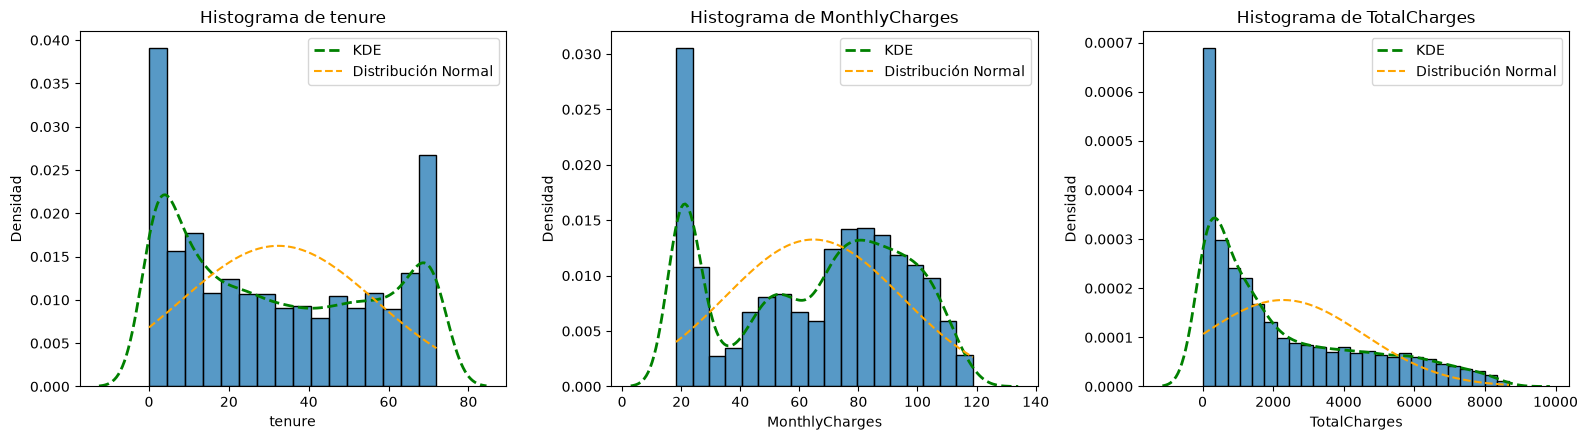

In [10]:
#Se genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, col in enumerate(num_cols):
    datos = eda_df[col].dropna()
    sns.histplot(x=datos, ax=axes[i], stat='density')
    sns.kdeplot(x=datos, ax=axes[i], color='green', linewidth=2, label='KDE', ls="dashed")
    x_vals = np.linspace(datos.min(), datos.max(), 1000)
    normal_ref = norm.pdf(x_vals, loc=datos.mean(), scale=datos.std())
    axes[i].plot(x_vals, normal_ref, color='orange', label='Distribución Normal', ls="dashed")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Densidad')
    axes[i].set_title(f'Histograma de {col}')
    axes[i].legend()

plt.tight_layout()
plt.show()

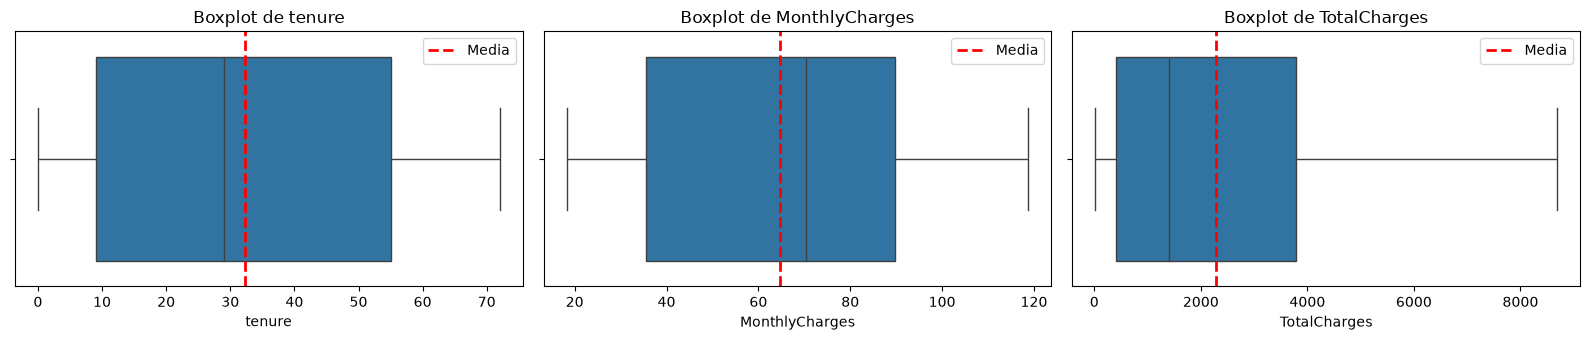

In [11]:
#Se crea un gráfico de boxplot individual para cada variable numérica que incluye la media
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))

for i, col in enumerate(num_cols):
    sns.boxplot(data=eda_df, x=col, ax=axes[i])
    axes[i].axvline(eda_df[col].mean(), color='red', linestyle='dashed', linewidth=2, label='Media')
    axes[i].legend()
    axes[i].set_title(f'Boxplot de {col}')

plt.tight_layout()
plt.show()

### 2.4 Composición del Portafolio de Clientes (Variables Categóricas)
Exploramos la adopción de servicios y características demográficas. Al evaluar la cardinalidad de cada variable, confirmamos que la mayoría presenta pocos niveles (e.g., binarias o de 3 a 4 opciones), lo cual hace viable una estrategia de *One-Hot Encoding* sin generar dispersión severa (sparsity) en los datos.

In [12]:
#Se obtienen las estadísticas descriptivas de las variables categóricas
eda_df[cat_cols + ['Churn']].astype('object').describe()

,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,2,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,Male,0,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,3555,5901,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174


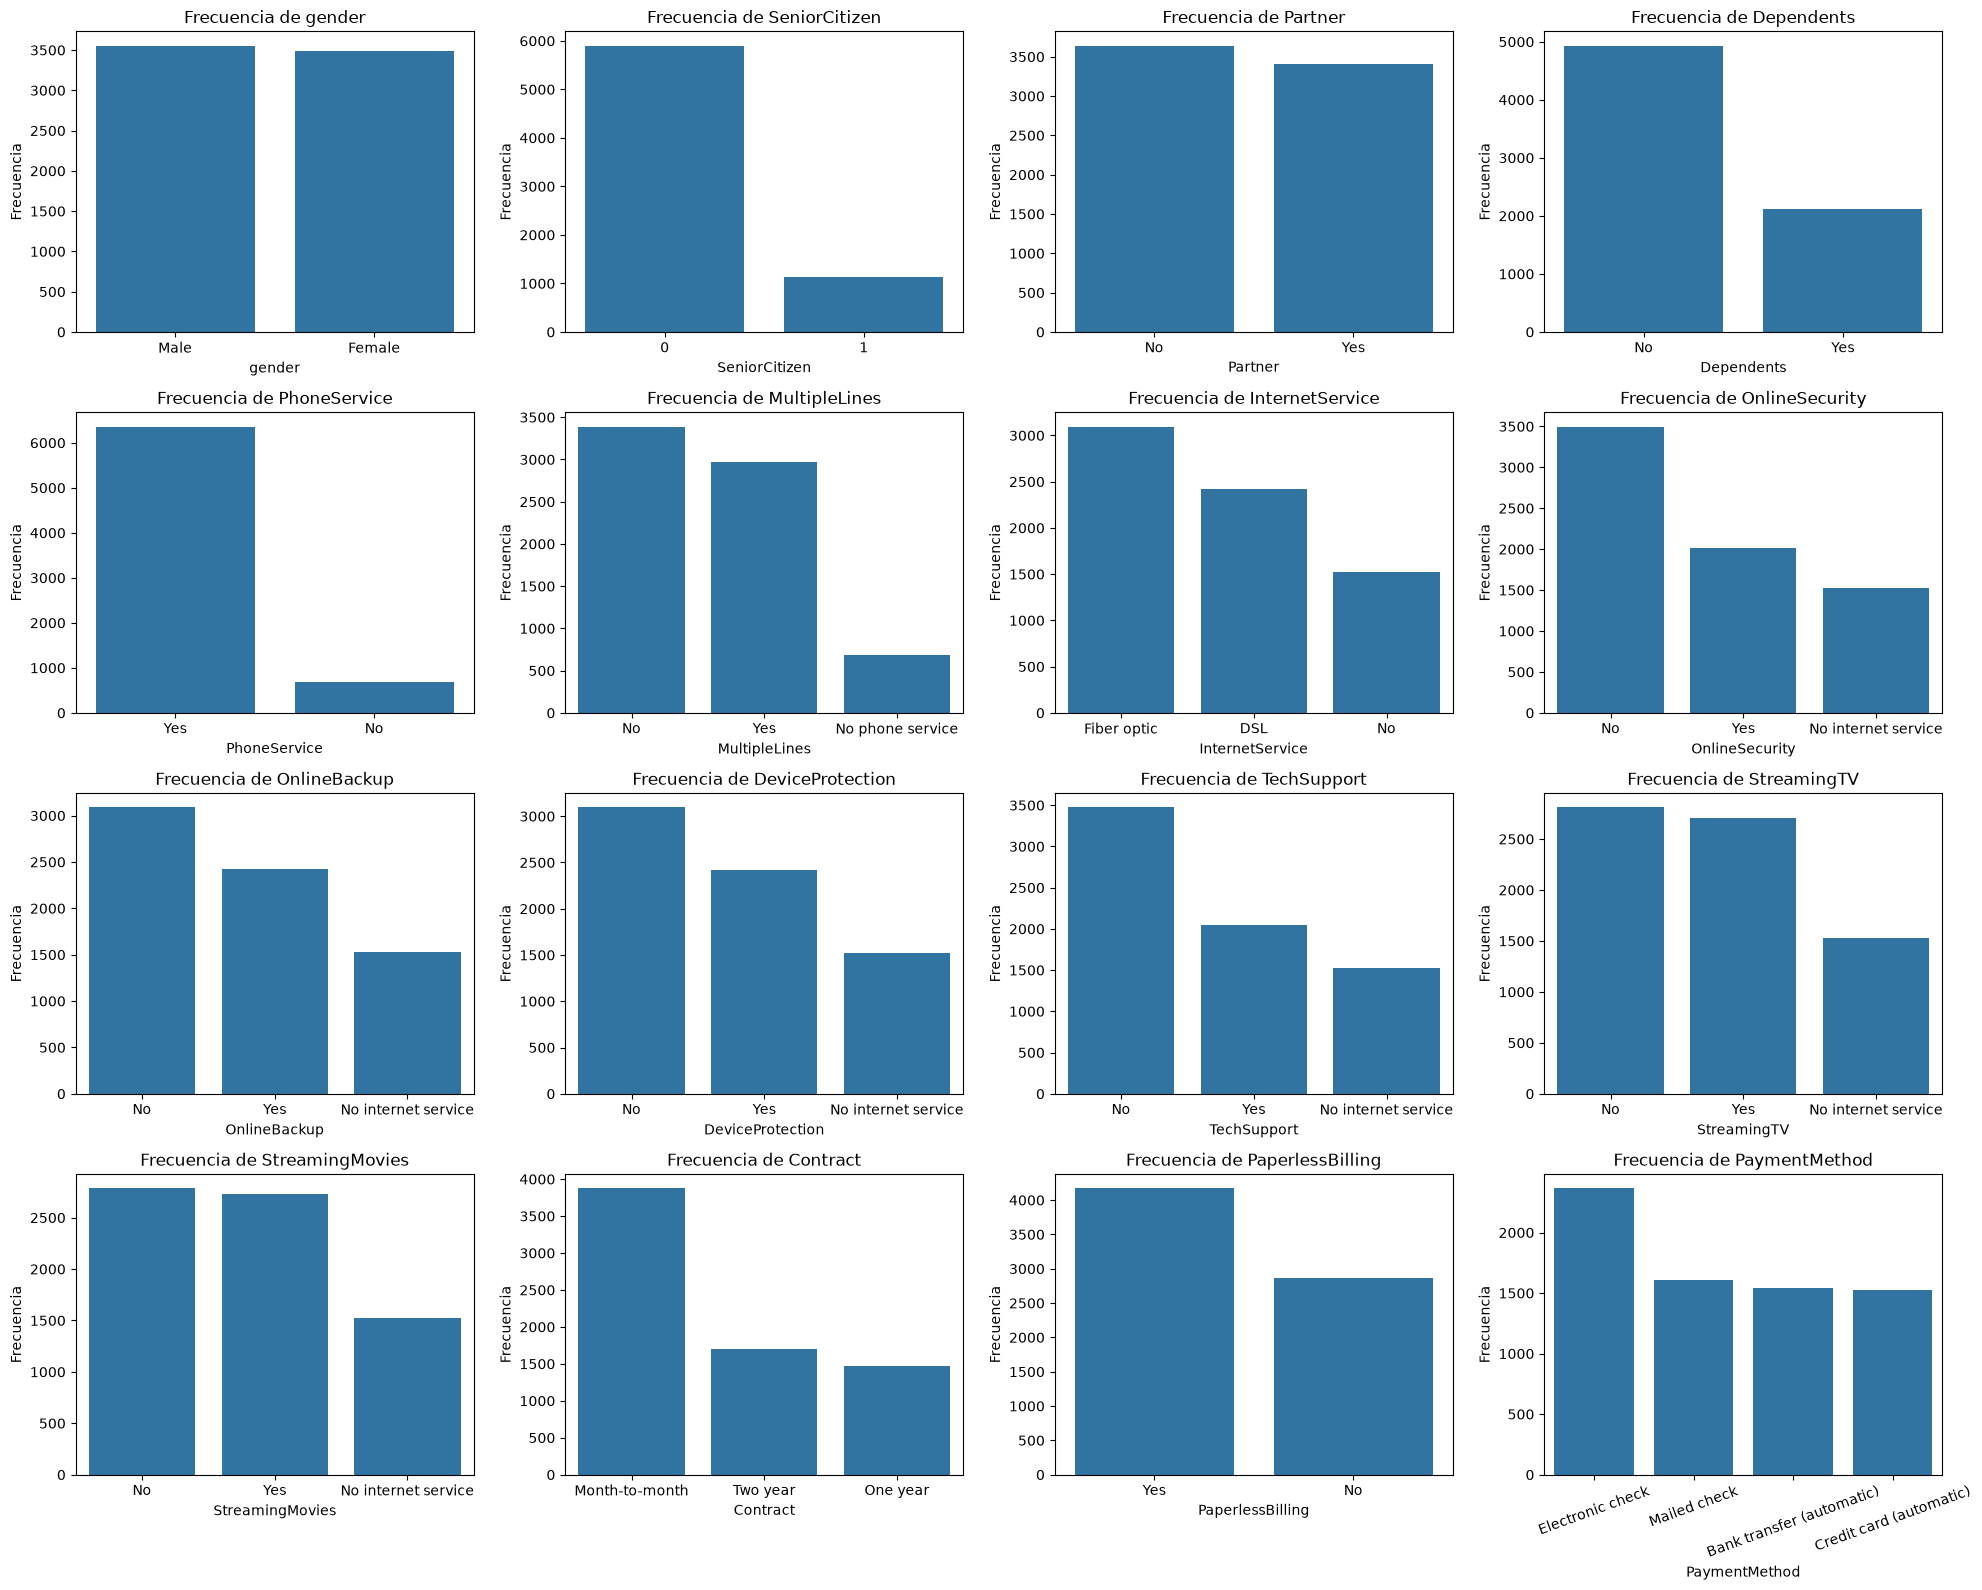

In [13]:
#Se genera un gráfico de barras para cada variable categórica
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    conteo = eda_df[col].value_counts()
    sns.barplot(x=conteo.index, y=conteo.values, ax=axes[i])
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frecuencia')
    axes[i].set_title(f'Frecuencia de {col}')
    if col == 'PaymentMethod':
        axes[i].tick_params(axis='x', labelrotation=20)

plt.tight_layout()
plt.show()

### 2.5 Distribución del Target (`Churn`)
El dataset presenta un desbalance evidente a favor de la retención: **73.5% de los clientes se mantienen y 26.5% han abandonado.** Este desbalance es crítico, pues dictará que la métrica de evaluación primaria no sea el Accuracy, sino ROC-AUC y F1-Score.

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

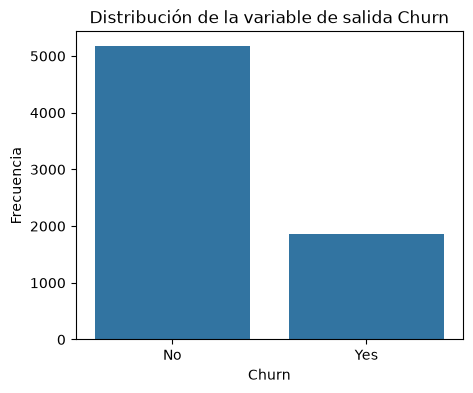

In [14]:
#Se analiza la distribución de la variable de salida Churn
display(eda_df['Churn'].value_counts())
display(eda_df['Churn'].value_counts(normalize=True))

conteo = eda_df['Churn'].value_counts()
plt.figure(figsize=(5, 4))
sns.barplot(x=conteo.index, y=conteo.values)
plt.title('Distribución de la variable de salida Churn')
plt.ylabel('Frecuencia')
plt.show()

## Análisis bivariado

### 2.6 Correlación Numérica (Multicolinealidad)
Al cruzar las variables continuas, observamos la correlación esperada entre `tenure` (antigüedad) y `TotalCharges` (cargos totales acumulados). Deberemos considerar si este nivel de correlación introduce ruido en modelos lineales como la Regresión Logística.

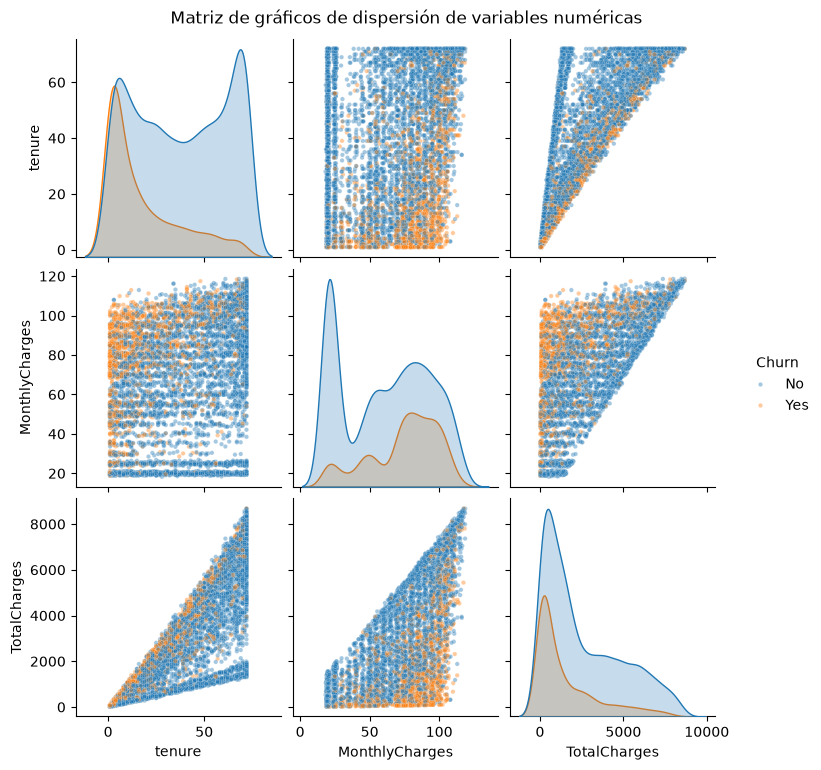

In [15]:
#Se obtiene la matriz de gráficos de dispersión de las variables numéricas, coloreada por Churn
sns.pairplot(eda_df[num_cols + ['Churn']].dropna(), hue='Churn', plot_kws={'alpha': 0.4, 's': 10})
plt.suptitle("Matriz de gráficos de dispersión de variables numéricas", y=1.02)
plt.show()

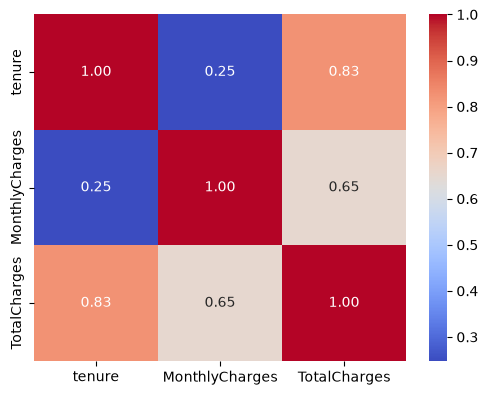

In [16]:
#Mapa de calor con los valores de correlación de Pearson
correlation_matrix = eda_df[num_cols].corr(method='pearson')
plt.figure(figsize=(6, 4.5))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f");

### 2.7 Factores de Riesgo Asociados al Churn
Este es el núcleo exploratorio: cruzamos todas las variables demográficas y de servicio contra la variable objetivo. Observamos señales claras de riesgo en clientes con baja antigüedad, contratos mensuales y servicio de fibra óptica (que podría tener problemas de calidad o costo percibido).

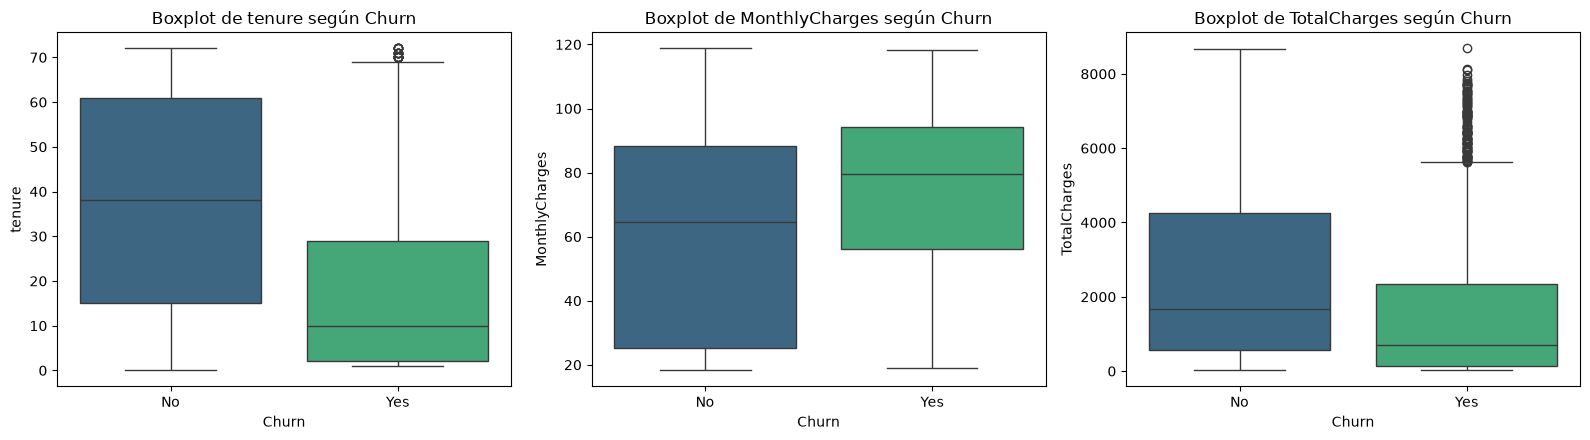

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.569965,61.265124,2555.344141
Yes,17.979133,74.441332,1531.796094


In [17]:
#Variables numéricas: box plots para comparar la distribución de cada variable según los valores de Churn
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, col in enumerate(num_cols):
    sns.boxplot(x='Churn', y=col, data=eda_df, ax=axes[i], palette='viridis', hue='Churn')
    axes[i].set_title(f'Boxplot de {col} según Churn')

plt.tight_layout()
plt.show()

#Promedio de cada variable numérica según Churn
eda_df.groupby('Churn')[num_cols].mean()

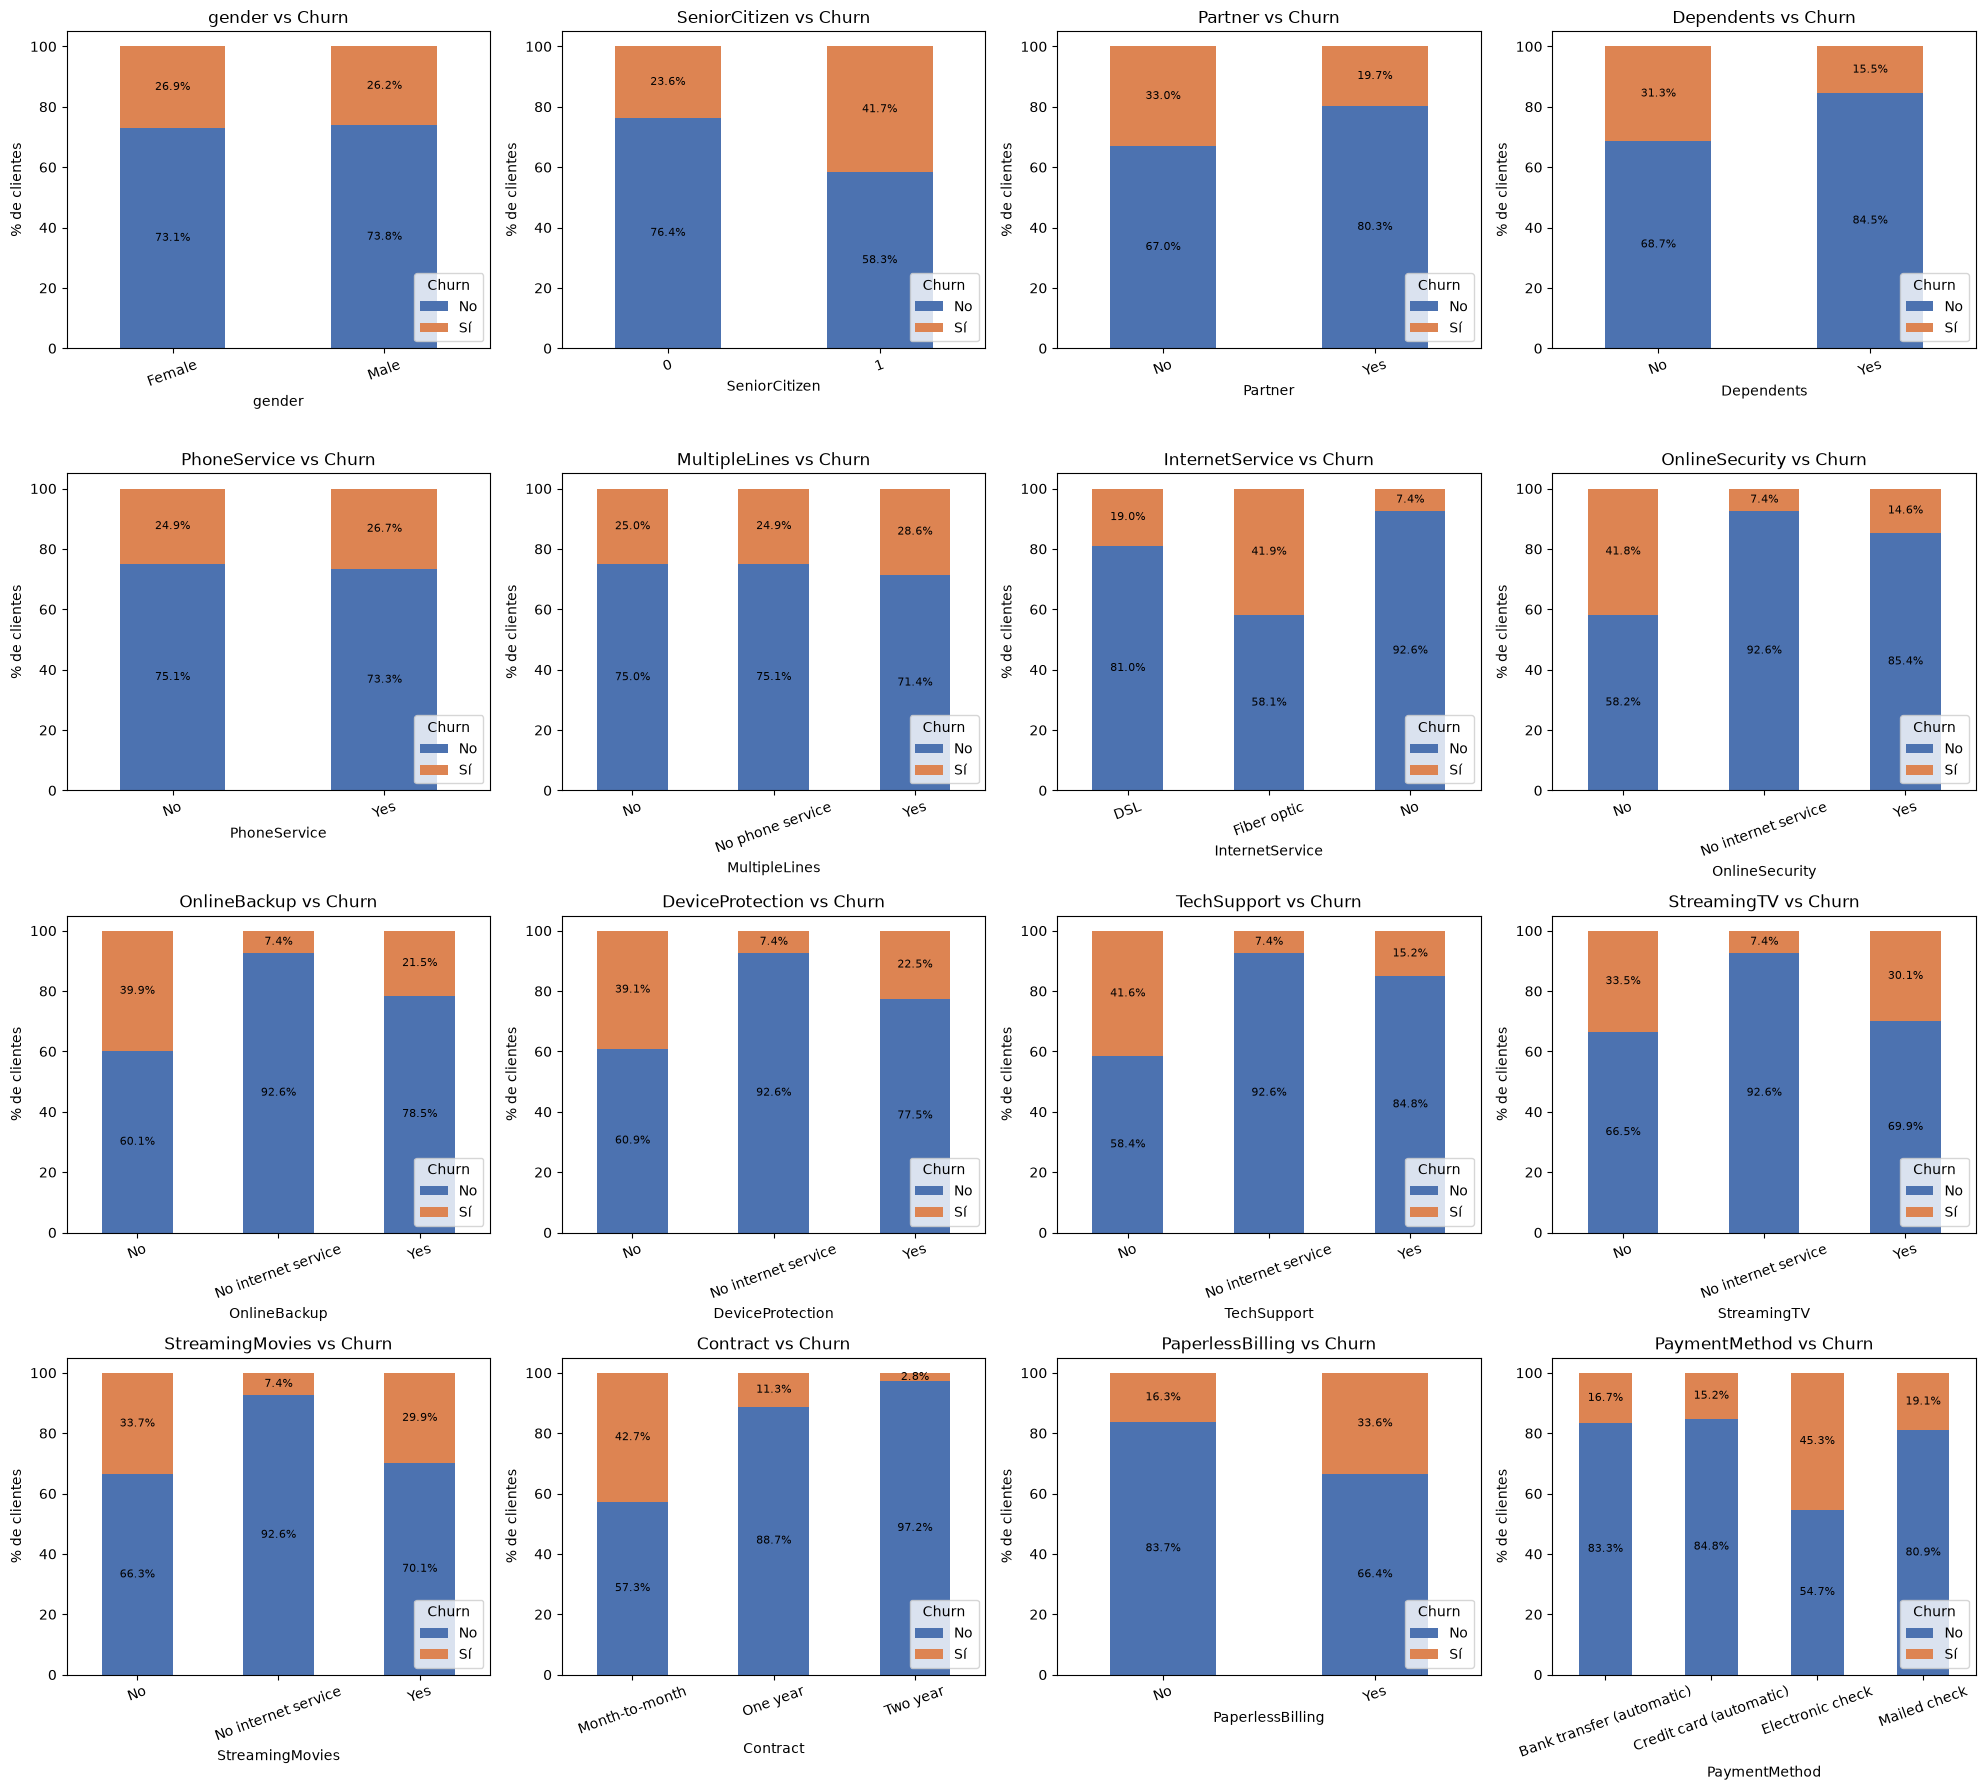

In [18]:
#Variables categóricas: gráficos de barras apiladas con la distribución relativa de Churn dentro de cada categoría
fig, axes = plt.subplots(4, 4, figsize=(20, 18))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    contingency_table = pd.crosstab(eda_df[col], eda_df['Churn'], normalize='index') * 100
    contingency_table.plot(kind='bar', stacked=True, ax=axes[i], color=['#4C72B0', '#DD8452'])
    #Se añaden los porcentajes
    for c in axes[i].containers:
        labels = [f'{w.get_height():.1f}%' if w.get_height() > 0 else '' for w in c]
        axes[i].bar_label(c, labels=labels, label_type='center', fontsize=8)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('% de clientes')
    axes[i].set_title(f'{col} vs Churn')
    axes[i].legend(['No', 'Sí'], title='Churn', loc='lower right')
    axes[i].tick_params(axis='x', labelrotation=20)

plt.tight_layout()
plt.show()

In [19]:
#Tasa de abandono (porcentaje de Churn = Yes) en las variables categóricas más relevantes
for col in ['Contract', 'InternetService', 'PaymentMethod', 'OnlineSecurity', 'TechSupport', 'gender', 'PhoneService']:
    tasa = pd.crosstab(eda_df[col], eda_df['Churn'], normalize='index')['Yes'].sort_values(ascending=False)
    print(f"--- {col} ---")
    print((tasa * 100).round(1).to_string(), "\n")

--- Contract ---
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8 

--- InternetService ---
InternetService
Fiber optic    41.9
DSL            19.0
No              7.4 

--- PaymentMethod ---
PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2 

--- OnlineSecurity ---
OnlineSecurity
No                     41.8
Yes                    14.6
No internet service     7.4 

--- TechSupport ---
TechSupport
No                     41.6
Yes                    15.2
No internet service     7.4 

--- gender ---
gender
Female    26.9
Male      26.2 

--- PhoneService ---
PhoneService
Yes    26.7
No     24.9 



# Paso 3: Limpieza de datos

### 3.1 Tratamiento de Errores de Tipado
Encontramos 11 registros donde `TotalCharges` contiene solo un espacio en blanco (' '). Corregimos el tipo forzándolo a numérico (float) para un tratamiento de nulos estandarizado.

In [20]:
#Se buscan los valores de TotalCharges que no se pueden convertir a número
no_numericos = churn_df[pd.to_numeric(churn_df['TotalCharges'], errors='coerce').isna()]['TotalCharges']
print("Registros con valores no numéricos:", len(no_numericos))
print(no_numericos.map(repr).value_counts())

Registros con valores no numéricos: 11
TotalCharges
' '    11
Name: count, dtype: int64


In [21]:
#Se convierte TotalCharges a tipo float, los espacios en blanco se convierten en NaN
churn_df['TotalCharges'] = pd.to_numeric(churn_df['TotalCharges'].str.strip().replace('', np.nan))
churn_df['TotalCharges'].dtype

dtype('float64')

### 3.2 Imputación de Valores Nulos
Tras la corrección de tipado, confirmamos 11 valores nulos en `TotalCharges`. Un análisis profundo revela que todos corresponden a clientes recién adquiridos (`tenure = 0`). Al no haber completado un ciclo de facturación, la acción lógica y sin riesgo de sesgo es rellenar (imputar) estos valores con `0`.


In [22]:
#Se revisan los valores nulos de cada columna
churn_df.isna().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [23]:
#Se muestran los registros con TotalCharges nulo, todos tienen tenure = 0 (clientes nuevos)
churn_df[churn_df['TotalCharges'].isna()][['tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'Churn']]

,tenure,MonthlyCharges,TotalCharges,Contract,Churn
customerID,,,,,
4472-LVYGI,0,52.55,NaN,Two year,No
3115-CZMZD,0,20.25,NaN,Two year,No
5709-LVOEQ,0,80.85,NaN,Two year,No
4367-NUYAO,0,25.75,NaN,Two year,No
1371-DWPAZ,0,56.05,NaN,Two year,No
7644-OMVMY,0,19.85,NaN,Two year,No
3213-VVOLG,0,25.35,NaN,Two year,No
2520-SGTTA,0,20.00,NaN,Two year,No
2923-ARZLG,0,19.70,NaN,One year,No


In [24]:
#Se imputan los valores nulos con 0, porque los clientes con tenure = 0 aún no han pagado nada
churn_df['TotalCharges'] = churn_df['TotalCharges'].fillna(0)
churn_df.isna().sum().sum()

np.int64(0)

### 3.3 Duplicados

Como `customerID` es el índice, `duplicated()` compara todas las demás columnas y encuentra 22 registros repetidos. Sin embargo, después comprobamos que no hay ningún `customerID` repetido, es decir, son clientes diferentes que tienen exactamente el mismo perfil (algo esperado con tantas variables categóricas y clientes nuevos con pocos meses). Por lo tanto, decidimos no eliminarlos, porque son clientes reales y borrarlos haría perder información.

In [25]:
#Se verifica si hay registros duplicados (sin tomar en cuenta el índice customerID)
churn_df.duplicated().sum()

np.int64(22)

In [26]:
#Se verifica si hay customerID repetidos
churn_df.index.duplicated().sum()

np.int64(0)

### 3.4 Tratamiento de Outliers
El análisis intercuartílico (IQR) y la verificación de 3 desviaciones estándar confirman la ausencia de valores extremos atípicos en las variables numéricas. Mantenemos la integridad del dataset original.

In [27]:
#Se buscan valores atípicos con el criterio IQR y con el de 3 desviaciones estándar
for col in num_cols:
    q1 = churn_df[col].quantile(0.25)
    q3 = churn_df[col].quantile(0.75)
    iqr = q3 - q1
    outliers_iqr = ((churn_df[col] < q1 - 1.5 * iqr) | (churn_df[col] > q3 + 1.5 * iqr)).sum()
    z = (churn_df[col] - churn_df[col].mean()) / churn_df[col].std()
    outliers_z = (z.abs() > 3).sum()
    print(f"{col}: min={churn_df[col].min()}, max={churn_df[col].max()}, outliers IQR={outliers_iqr}, outliers 3 std={outliers_z}")

tenure: min=0, max=72, outliers IQR=0, outliers 3 std=0
MonthlyCharges: min=18.25, max=118.75, outliers IQR=0, outliers 3 std=0
TotalCharges: min=0.0, max=8684.8, outliers IQR=0, outliers 3 std=0


In [28]:
#Se revisa que TotalCharges sea congruente con tenure * MonthlyCharges (solo clientes con tenure > 0)
clientes = churn_df[churn_df['tenure'] > 0]
razon = clientes['TotalCharges'] / (clientes['tenure'] * clientes['MonthlyCharges'])
razon.describe()

count    7032.000000
mean        1.000275
std         0.051159
min         0.689356
25%         0.979546
50%         1.000000
75%         1.019562
max         1.573454
dtype: float64

### 3.5 Homologación Categórica
Verificamos la consistencia de los strings (ausencia de errores tipográficos o clases ocultas). Convertimos `SeniorCitizen` a su representación categórica natural (Sí/No) para facilitar la posterior binarización.

In [29]:
#Se revisan los valores únicos de las variables de texto
for col in churn_df.select_dtypes(include='object').columns:
    print(col, sorted(churn_df[col].unique()))

gender ['Female', 'Male']
Partner ['No', 'Yes']
Dependents ['No', 'Yes']
PhoneService ['No', 'Yes']
MultipleLines ['No', 'No phone service', 'Yes']
InternetService ['DSL', 'Fiber optic', 'No']
OnlineSecurity ['No', 'No internet service', 'Yes']
OnlineBackup ['No', 'No internet service', 'Yes']
DeviceProtection ['No', 'No internet service', 'Yes']
TechSupport ['No', 'No internet service', 'Yes']
StreamingTV ['No', 'No internet service', 'Yes']
StreamingMovies ['No', 'No internet service', 'Yes']
Contract ['Month-to-month', 'One year', 'Two year']
PaperlessBilling ['No', 'Yes']
PaymentMethod ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn ['No', 'Yes']


In [30]:
#Se efectúan las conversiones de tipo
churn_df['SeniorCitizen'] = churn_df['SeniorCitizen'].replace({1: 'Yes', 0: 'No'})

for col in cat_cols:
    churn_df[col] = churn_df[col].astype('category')

churn_df['Contract'] = pd.Categorical(churn_df['Contract'],
                                      categories=['Month-to-month', 'One year', 'Two year'], ordered=True)

churn_df['Churn'] = churn_df['Churn'].replace({'Yes': 1, 'No': 0}).astype(int)
churn_df.info()

<class 'pandas.DataFrame'>
Index: 7043 entries, 7590-VHVEG to 3186-AJIEK
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   gender            7043 non-null   category
 1   SeniorCitizen     7043 non-null   category
 2   Partner           7043 non-null   category
 3   Dependents        7043 non-null   category
 4   tenure            7043 non-null   int64   
 5   PhoneService      7043 non-null   category
 6   MultipleLines     7043 non-null   category
 7   InternetService   7043 non-null   category
 8   OnlineSecurity    7043 non-null   category
 9   OnlineBackup      7043 non-null   category
 10  DeviceProtection  7043 non-null   category
 11  TechSupport       7043 non-null   category
 12  StreamingTV       7043 non-null   category
 13  StreamingMovies   7043 non-null   category
 14  Contract          7043 non-null   category
 15  PaperlessBilling  7043 non-null   category
 16  PaymentMethod     7043 no

### 3.6 Resumen de las decisiones de limpieza

| Problema | Decisión | Registros afectados |
|---|---|---|
| `TotalCharges` leída como texto | Se convierte a `float` | 7,043 |
| 11 nulos en `TotalCharges` (clientes con `tenure` = 0) | Se imputan con 0 | 11 |
| `SeniorCitizen` como número 0/1 | Se convierte a No/Yes (`category`) | 7,043 |
| 22 perfiles iguales con distinto `customerID` | Se conservan (son clientes distintos) | 0 |
| Outliers | No se encontraron (IQR y 3 std) | 0 |
| `customerID` | Se usa como índice, no entra al modelo | — |

**El dataset final conserva los 7,043 registros, 19 variables de entrada y la variable de salida `Churn`.**

In [31]:
#Se guarda la tabla de decisiones de limpieza para registrarla como artefacto en MLflow
bitacora = pd.DataFrame({
    'problema': ['TotalCharges como texto', 'Nulos en TotalCharges', 'SeniorCitizen 0/1',
                 'Perfiles duplicados', 'Outliers', 'customerID'],
    'decision': ['Convertir a float', 'Imputar con 0 (tenure = 0)', 'Convertir a No/Yes',
                 'Se conservan (distinto customerID)', 'No se encontraron', 'Se usa como índice'],
})
bitacora.to_csv('data/interim/bitacora_limpieza.csv', index=False)
print("Registros finales:", churn_df.shape[0], "| Variables:", churn_df.shape[1])

Registros finales: 7043 | Variables: 20


# Paso 4: Entrenamiento del modelo base

### 4.1 Elección del Algoritmo Baseline
Para establecer nuestro punto de referencia, implementaremos una **Regresión Logística**. Su naturaleza paramétrica, interpretabilidad de los coeficientes y rapidez la hacen ideal como Benchmark contra el cual comparar algoritmos más complejos en el futuro.


### 4.2 Split Estratificado de Datos
Segmentamos la muestra en 80% Entrenamiento y 20% Prueba. Aplicamos muestreo estratificado sobre la variable `Churn` para garantizar que la prevalencia de abandono (26.5%) se mantenga equitativa en ambos conjuntos.

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

#Se separan las variables de entrada (X) y la variable de salida (y)
X = churn_df.drop(columns='Churn')
y = churn_df['Churn']

#División estratificada 80% entrenamiento / 20% prueba
TEST_SIZE = 0.2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

print("Entrenamiento:", X_train.shape, "| % Churn:", round(y_train.mean() * 100, 1))
print("Prueba:", X_test.shape, "| % Churn:", round(y_test.mean() * 100, 1))

Entrenamiento: (5634, 19) | % Churn: 26.5
Prueba: (1409, 19) | % Churn: 26.5


### 4.3 Pipeline de Modelado (Entrenamiento)
Para evitar fugas de datos (Data Leakage) e inconsistencias, orquestamos el escalado numérico (`StandardScaler`) y la codificación categórica (`OneHotEncoder`) mediante un objeto `Pipeline` de Scikit-Learn. Posteriormente, ajustamos (entrenamos) el modelo con el subconjunto de entrenamiento.

In [33]:
#Hiperparámetros del modelo base
MODEL_PARAMS = {'C': 1.0, 'penalty': 'l2', 'solver': 'lbfgs', 'max_iter': 1000, 'random_state': SEED}

#Preprocesamiento: escalado de numéricas y one-hot encoding de categóricas
preprocesador = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), cat_cols),
])

#Pipeline con el preprocesamiento y el modelo
modelo = Pipeline([
    ('preprocesamiento', preprocesador),
    ('clasificador', LogisticRegression(**MODEL_PARAMS)),
])

#Se entrena el modelo base y el modelo Dummy de referencia
modelo.fit(X_train, y_train)
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)

print("Número de variables después del one-hot encoding:",
      len(modelo.named_steps['preprocesamiento'].get_feature_names_out()))

Número de variables después del one-hot encoding: 40


# Paso 5: Evaluación del modelo

### 5.1 Selección de Métricas para Data Desbalanceada
Dado que el costo de no predecir a un cliente en riesgo (falso negativo) es alto para el negocio, nos basaremos en **ROC-AUC** para la capacidad de separación general, y en **Recall** y **F1-Score** para medir la efectividad en la clase positiva (Churn).

### 5.2 Desempeño del Modelo vs Benchmark Ingenuo (Dummy)
Comparamos la Regresión Logística contra un modelo Dummy (que siempre predice la clase mayoritaria). La superación del Baseline ingenuo nos indica que nuestro modelo efectivamente está capturando patrones de comportamiento.


In [34]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

#Función para calcular las métricas de un modelo
def evaluar(m, X_, y_):
    pred = m.predict(X_)
    proba = m.predict_proba(X_)[:, 1]
    return {'accuracy': accuracy_score(y_, pred),
            'precision': precision_score(y_, pred, zero_division=0),
            'recall': recall_score(y_, pred),
            'f1': f1_score(y_, pred),
            'roc_auc': roc_auc_score(y_, proba),
            'pr_auc': average_precision_score(y_, proba)}

metricas_dummy = evaluar(dummy, X_test, y_test)
metricas_train = evaluar(modelo, X_train, y_train)
metricas_test = evaluar(modelo, X_test, y_test)

pd.DataFrame({'Dummy (prueba)': metricas_dummy,
              'LogReg (entrenamiento)': metricas_train,
              'LogReg (prueba)': metricas_test}).T.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc
Dummy (prueba),0.7346,0.0000,0.0000,0.0000,0.5000,0.2654
LogReg (entrenamiento),0.8058,0.6613,0.5498,0.6004,0.8493,0.6669
LogReg (prueba),0.8055,0.6572,0.5588,0.6040,0.8420,0.6336


In [35]:
#Reporte de clasificación en el conjunto de prueba
y_pred = modelo.predict(X_test)
y_proba = modelo.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred, target_names=['No churn', 'Churn'], digits=3))

              precision    recall  f1-score   support

    No churn      0.849     0.895     0.871      1035
       Churn      0.657     0.559     0.604       374

    accuracy                          0.806      1409
   macro avg      0.753     0.727     0.738      1409
weighted avg      0.798     0.806     0.800      1409



### 5.3 Evaluación Visual de la Clasificación
La Matriz de Confusión detalla los aciertos y errores (Falsos Positivos y Negativos). Las curvas ROC y Precision-Recall nos ilustran la sensibilidad del modelo ante variaciones en el umbral probabilístico de clasificación.


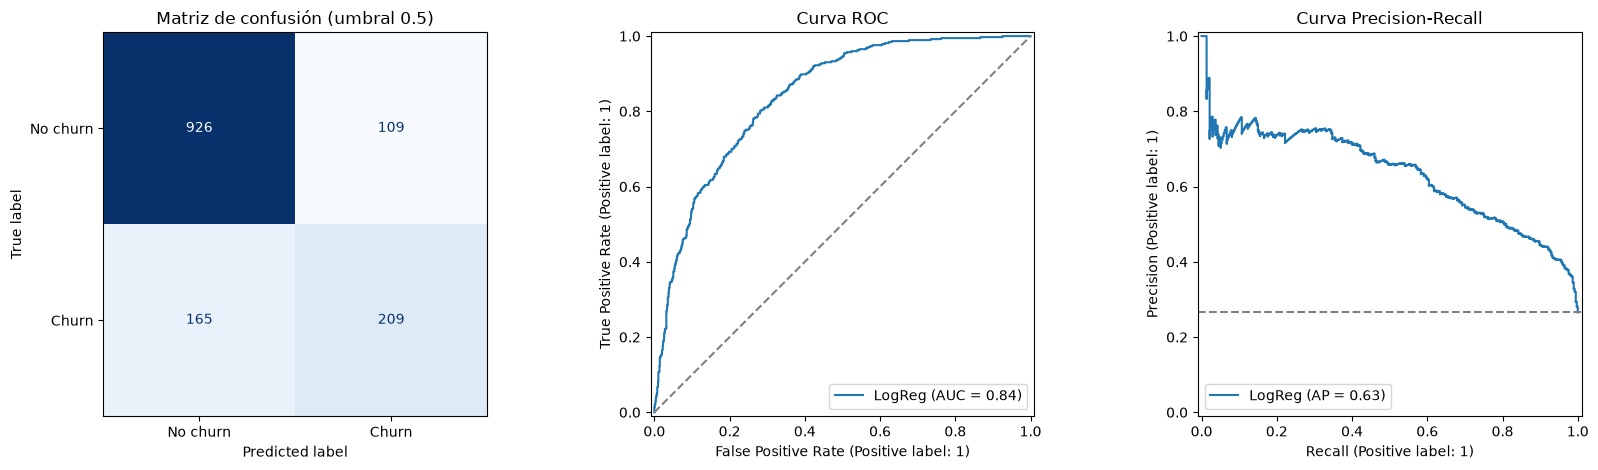

Verdaderos negativos=926, Falsos positivos=109, Falsos negativos=165, Verdaderos positivos=209


In [36]:
#Matriz de confusión, curva ROC y curva Precision-Recall
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No churn', 'Churn'],
                                        cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title('Matriz de confusión (umbral 0.5)')
axes[0].grid(False)

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name='LogReg')
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set_title('Curva ROC')

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[2], name='LogReg')
axes[2].axhline(y_test.mean(), ls='--', color='gray')
axes[2].set_title('Curva Precision-Recall')

plt.tight_layout()
fig.savefig('reports/figures/evaluacion_baseline.png', dpi=110)
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"Verdaderos negativos={tn}, Falsos positivos={fp}, Falsos negativos={fn}, Verdaderos positivos={tp}")

### 5.4 Interpretabilidad: Impulsores y Retractores de Churn
Al extraer los coeficientes de la Regresión Logística, podemos identificar los *Drivers* principales. Coeficientes positivos indican un incremento en el riesgo (ej. Internet de Fibra Óptica, Contrato Mes a Mes), mientras que los negativos reducen el riesgo (ej. Contratos a dos años, Antigüedad prolongada).

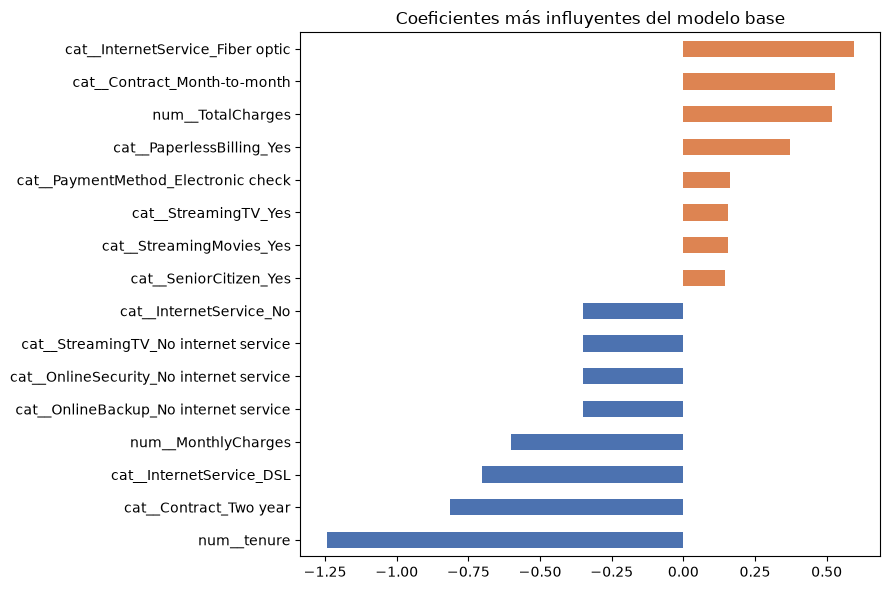

In [37]:
#Coeficientes más importantes del modelo (positivos aumentan el riesgo de churn, negativos lo disminuyen)
nombres = modelo.named_steps['preprocesamiento'].get_feature_names_out()
coeficientes = pd.Series(modelo.named_steps['clasificador'].coef_[0], index=nombres).sort_values()
top = pd.concat([coeficientes.head(8), coeficientes.tail(8)])

fig, ax = plt.subplots(figsize=(9, 6))
top.plot(kind='barh', ax=ax, color=['#4C72B0' if v < 0 else '#DD8452' for v in top])
ax.set_title('Coeficientes más influyentes del modelo base')
plt.tight_layout()
fig.savefig('reports/figures/coeficientes_baseline.png', dpi=110)
plt.show()

### 5.5 Calibración Estratégica del Umbral
El umbral por defecto (0.5) puede no ser óptimo comercialmente. Si el departamento de Marketing dispone de presupuesto para campañas de retención económicas, podríamos reducir el umbral (e.g. 0.3) para captar a más clientes en riesgo, sacrificando precisión a favor del alcance (Recall).


In [38]:
#Efecto de cambiar el umbral de decisión
resultados_umbral = []
for umbral in [0.3, 0.4, 0.5, 0.6]:
    pred = (y_proba >= umbral).astype(int)
    resultados_umbral.append({'umbral': umbral,
                              'precision': precision_score(y_test, pred),
                              'recall': recall_score(y_test, pred),
                              'f1': f1_score(y_test, pred)})
pd.DataFrame(resultados_umbral).round(3)

,umbral,precision,recall,f1
0,0.3,0.519,0.754,0.615
1,0.4,0.568,0.668,0.614
2,0.5,0.657,0.559,0.604
3,0.6,0.718,0.401,0.515


### 5.6 Interpretación de los resultados

**1. El modelo sí aprende patrones reales.** **El ROC-AUC en prueba es de 0.842. Esto significa que si se toma al azar un cliente que abandonó y uno que no, el modelo le da mayor probabilidad de abandono al que realmente se fue en el 84% de los casos. El modelo Dummy tiene 0.50, que es lo mismo que adivinar al azar, así que la mejora es grande. El PR-AUC (0.634) también es mucho mayor que el 0.265 que se obtendría al azar.**

**2. La exactitud es engañosa.** **El modelo tiene 80.6% de exactitud, pero el Dummy, que nunca detecta a ningún cliente que se va, ya tiene 73.5%. La mejora real en exactitud es de solo 7 puntos, lo que confirma que no debe ser la métrica principal en un problema desbalanceado.**

**3. Desempeño en la clase Churn (umbral 0.5):**
- **Recall = 0.559: de los 374 clientes que realmente abandonaron en el conjunto de prueba, el modelo detectó 209 y no detectó 165. Es decir, se le escapa casi la mitad de los clientes en riesgo, y esta es la principal debilidad del modelo base.**
- **Precision = 0.657: de los 318 clientes que el modelo marcó como riesgo, 2 de cada 3 realmente se fueron; 109 fueron falsas alarmas.**
- **F1 = 0.604: balance moderado entre precision y recall.**
- **La clase No churn se predice mucho mejor (F1 = 0.871) porque es la clase mayoritaria.**

**4. No hay sobreajuste.** **Las métricas de entrenamiento (ROC-AUC 0.849, F1 0.600) y de prueba (ROC-AUC 0.842, F1 0.604) son casi iguales, por lo que el modelo generaliza bien. Al ser un modelo lineal y sencillo, más bien podría tener algo de subajuste, lo cual es normal para un modelo base.**

**5. El umbral es importante para el negocio.** **Si el umbral baja de 0.5 a 0.3, el recall sube a 0.754 (se detectan 3 de cada 4 clientes que se van) y la precision baja a 0.519, con un F1 casi igual. Como perder un cliente normalmente cuesta más que ofrecerle una promoción para que se quede, en la práctica convendría un umbral menor a 0.5. La elección del umbral se deja para la etapa de ajuste del modelo.**

**6. Coeficientes del modelo.** **Los coeficientes coinciden con lo observado en el EDA: la antigüedad (`tenure`) es la variable que más reduce el riesgo, seguida del contrato de dos años y el internet DSL. Las que más lo aumentan son la fibra óptica, el contrato mes a mes, la facturación electrónica y el pago con cheque electrónico. El coeficiente negativo de `MonthlyCharges` y positivo de `TotalCharges` parece contradecir el EDA, pero no significa que pagar más reduzca el abandono: se debe a la multicolinealidad entre `tenure`, `MonthlyCharges` y `TotalCharges` que se observó en el mapa de calor, por lo que esos coeficientes deben leerse con cuidado.**

**Conclusión: el modelo base (Regresión Logística con ROC-AUC 0.842, F1 0.604 y Recall 0.559) es un punto de partida sólido y reproducible. Cualquier modelo futuro (árboles de decisión, boosting, balanceo de clases, ajuste del umbral o nuevas variables) debe superar estas métricas con la misma división de datos para justificar su uso.**


# Paso 6: Registro del experimento en MLflow

### 6.1 Trazabilidad del Experimento (MLFlow)
Para garantizar las mejores prácticas de MLOps, conectamos nuestra sesión a un servidor local de MLFlow. Esto nos permitirá registrar métricas, hiperparámetros y serializar el artefacto del modelo para un futuro despliegue.

```bash
mlflow server --host 127.0.0.1 --port 8080
```

In [39]:
import mlflow
import mlflow.sklearn
from mlflow import MlflowClient
from mlflow.models import infer_signature
from pprint import pprint

from dotenv import load_dotenv

#Se cargan las variables de entorno (.env) y se usa la MISMA dirección para mlflow y para el cliente
load_dotenv()
TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "http://127.0.0.1:5000")
mlflow.set_tracking_uri(TRACKING_URI)
client = MlflowClient(tracking_uri=TRACKING_URI)

#Se listan los experimentos que existen en el servidor
pprint([e.name for e in client.search_experiments()])

['Telco_Churn_Baseline', 'Apple_Models', 'Hello MLflow', 'Default']


### 6.2 Creación del experimento

Generamos un nuevo experimento etiquetado como `Telco_Churn_Baseline` en el tracking server. Se agregan metadatos de entorno y objetivo del proyecto.

In [40]:
EXPERIMENT_NAME = "Telco_Churn_Baseline"

#Descripción que aparece en la interfaz de MLflow
experiment_description = (
    "Proyecto de predicción de abandono de clientes (churn) de una compañía de telecomunicaciones. "
    "Este experimento contiene el modelo base (baseline) contra el que se compararán los siguientes modelos."
)

#Etiquetas del experimento para poder buscarlo
experiment_tags = {
    "project_name": "telco-churn",
    "dataset": "blastchar/telco-customer-churn",
    "problem": "binary_classification",
    "author": "A01797668",
    "mlflow.note.content": experiment_description,
}

#Se crea el experimento solo si no existe
experimento = client.get_experiment_by_name(EXPERIMENT_NAME)
if experimento is None:
    experiment_id = client.create_experiment(name=EXPERIMENT_NAME, tags=experiment_tags)
    print("Experimento creado con id:", experiment_id)
else:
    experiment_id = experimento.experiment_id
    print("El experimento ya existía, id:", experiment_id)

#Se activa el experimento para los siguientes runs
experimento_activo = mlflow.set_experiment(EXPERIMENT_NAME)
print("Experimento activo:", experimento_activo.name)

El experimento ya existía, id: 3
Experimento activo: Telco_Churn_Baseline


### 6.3 Logging de la Ejecución (Run)
Dentro de un contexto activo (Run) en MLFlow, inyectamos (log) la configuración del clasificador (penalty, C), las métricas de prueba obtenidas (ROC-AUC, F1, Recall) y procedemos a guardar el pipeline serializado.

In [41]:
#Se guarda el reporte de clasificación en un archivo de texto
with open('reports/classification_report.txt', 'w') as f:
    f.write(classification_report(y_test, y_pred, target_names=['No churn', 'Churn'], digits=3))

run_name = "logreg_baseline"
artifact_path = "modelo_baseline"

with mlflow.start_run(run_name=run_name) as run:
    #Parámetros
    mlflow.log_params({f"model_{k}": v for k, v in MODEL_PARAMS.items()})
    mlflow.log_params({
        "model_type": "LogisticRegression",
        "test_size": TEST_SIZE,
        "stratify": True,
        "seed": SEED,
        "scaler": "StandardScaler",
        "encoder": "OneHotEncoder(drop=if_binary)",
        "n_rows": churn_df.shape[0],
        "n_features_raw": X.shape[1],
        "n_features_encoded": len(nombres),
        "totalcharges_imputation": "0 when tenure==0",
    })

    #Métricas
    mlflow.log_metrics({f"test_{k}": v for k, v in metricas_test.items()})
    mlflow.log_metrics({f"train_{k}": v for k, v in metricas_train.items()})
    mlflow.log_metrics({f"dummy_test_{k}": v for k, v in metricas_dummy.items()})

    #Etiquetas del run
    mlflow.set_tags({"stage": "baseline", "model_family": "linear"})

    #Artefactos: gráficas, tabla de limpieza y reporte
    mlflow.log_artifact('reports/figures/evaluacion_baseline.png', artifact_path='figuras')
    mlflow.log_artifact('reports/figures/coeficientes_baseline.png', artifact_path='figuras')
    mlflow.log_artifact('data/interim/bitacora_limpieza.csv', artifact_path='datos')
    mlflow.log_artifact('reports/classification_report.txt', artifact_path='reportes')

    #Artefacto: modelo con firma y un ejemplo pequeño de entrada
    firma = infer_signature(X_train, modelo.predict(X_train))
    mlflow.sklearn.log_model(sk_model=modelo, name=artifact_path,
                             signature=firma, input_example=X_train.head(5))

    run_id = run.info.run_id

print("Run ID:", run_id)

🏃 View run logreg_baseline at: http://127.0.0.1:5000/#/experiments/3/runs/1e1902253f7b4428a17d6fb4370a489e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3
Run ID: 1e1902253f7b4428a17d6fb4370a489e


### 6.4 Validación del Registro
Para comprobar la correcta persistencia del experimento, consultamos el API de MLFlow, recuperando las métricas guardadas y cargando nuevamente el artefacto serializado del pipeline.


In [42]:
#Se consultan los runs del experimento en el servidor
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME])
display(runs[['run_id', 'tags.mlflow.runName', 'status', 'params.model_type',
              'metrics.test_roc_auc', 'metrics.test_recall', 'metrics.test_f1']])

#Se vuelve a cargar el modelo desde MLflow para comprobar que se guardó correctamente
modelo_cargado = mlflow.sklearn.load_model(f"runs:/{run_id}/{artifact_path}")
print("ROC-AUC del modelo cargado desde MLflow:",
      round(roc_auc_score(y_test, modelo_cargado.predict_proba(X_test)[:, 1]), 4))

,run_id,tags.mlflow.runName,status,params.model_type,metrics.test_roc_auc,metrics.test_recall,metrics.test_f1
0,1e1902253f7b4428a17d6fb4370a489e,logreg_baseline,FINISHED,LogisticRegression,0.84197,0.558824,0.604046
1,8a998d2e4a604870a1c50e0c0731d83b,logreg_baseline,FINISHED,LogisticRegression,0.84197,0.558824,0.604046
2,1c5016211e1c4864be6b12af3561b9ed,logreg_baseline,FINISHED,LogisticRegression,0.84197,0.558824,0.604046
3,c14e447957534746a6475cbe5b0b08f9,logreg_baseline,FINISHED,LogisticRegression,0.84197,0.558824,0.604046


ROC-AUC del modelo cargado desde MLflow: 0.842


### 6.5 Evidencia de registro de experimento en MLflow
Se muestran 3 imágenes que demuestran el registro exitoso del experimento en la herramienta MLflow


#### 6.5.1 Pantalla inicial de MLflow

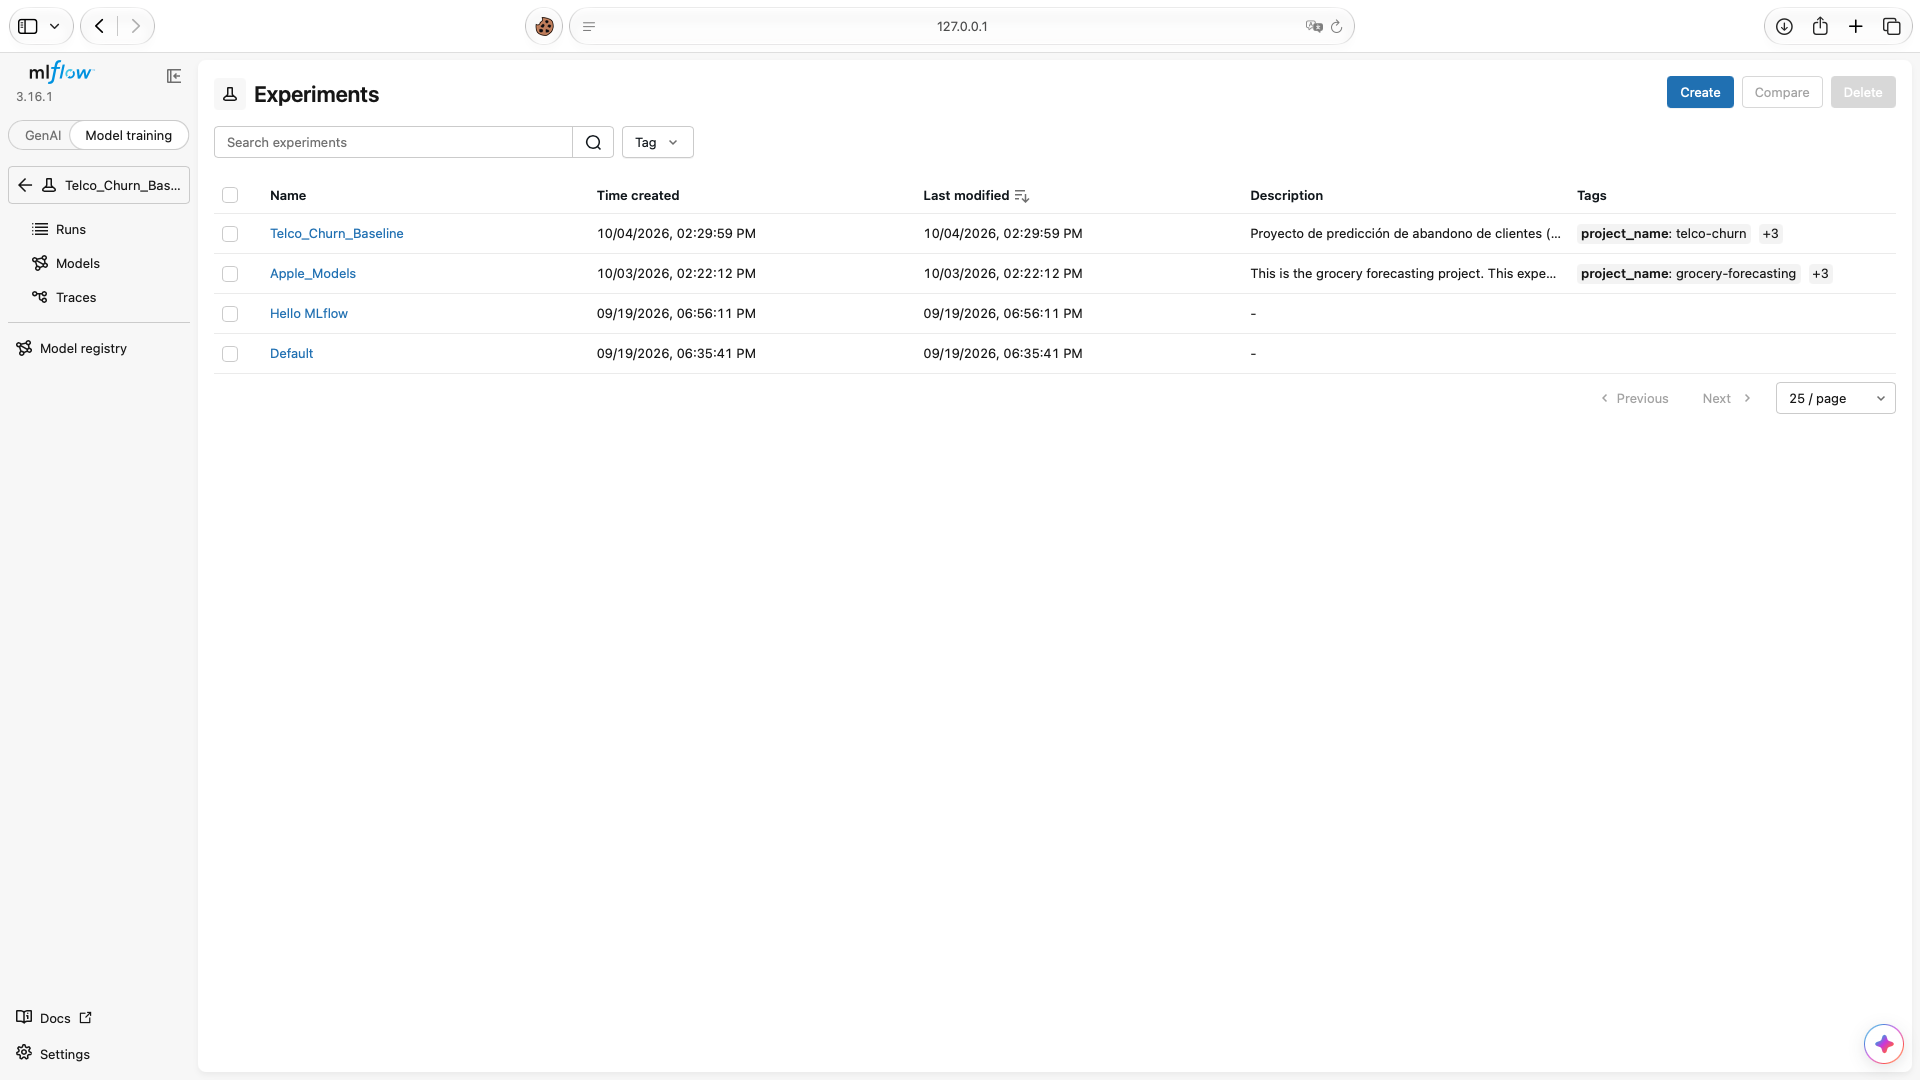

#### 6.5.2 Pantalla al dar click en el experimento: “Telco_Churn_Baseline”.

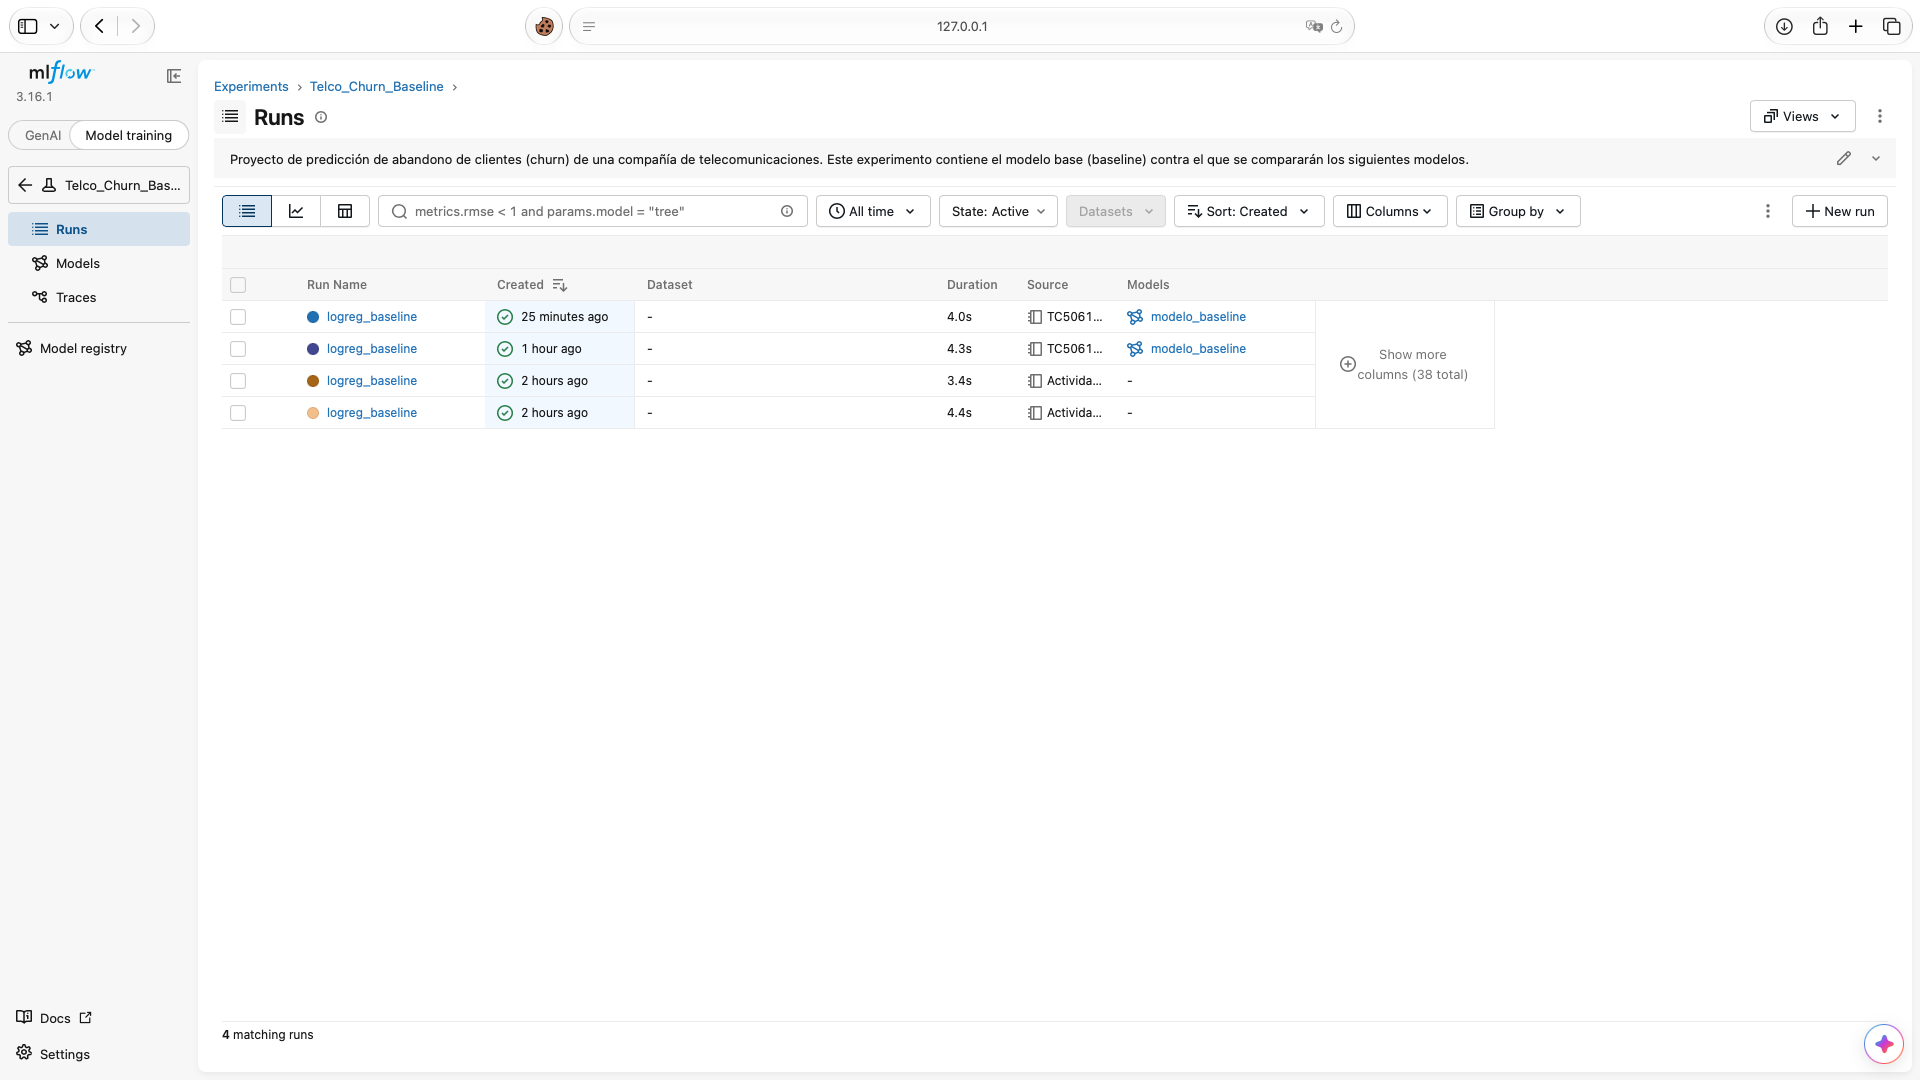

#### 6.5.3 Pantalla al dar click en el primer "Run Name": “logreg_baseline” ejecutado.

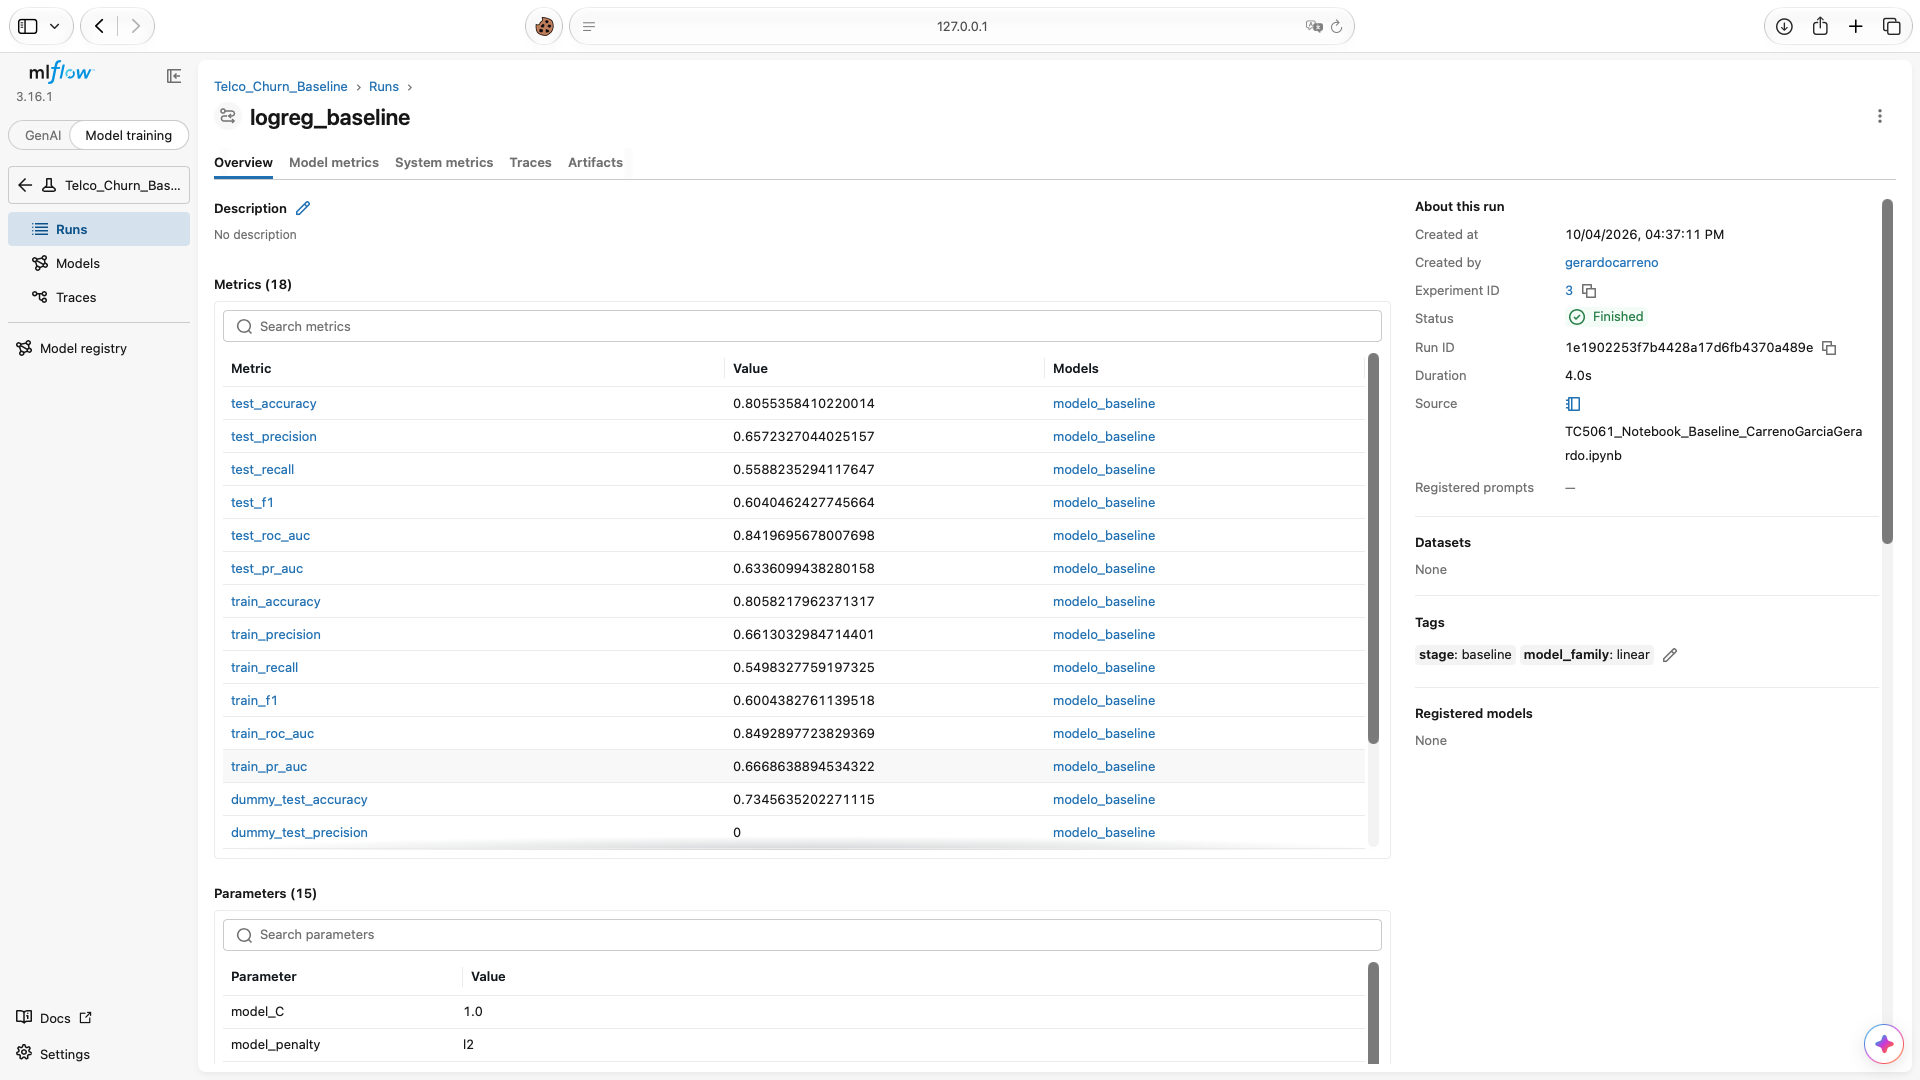

# Paso 7: Reflexión

**¿Qué mejoraría aplicando prácticas de MLOps y por qué?**

Para optimizar este flujo base, el primer paso sería transicionar de un entorno de experimentación manual, en el que la notebook se ejecuta celda por celda y en orden, a un pipeline completamente automatizado con etapas independientes para la carga, limpieza, entrenamiento y evaluación del modelo. Implementaría los contenedores necesarios del entorno utilizando herramientas como Podman para garantizar que las bibliotecas y dependencias operen de manera idéntica en cualquier infraestructura local o de servidor. También versionaría los datos con herramientas como DVC, o al menos registrando el hash del dataset en MLflow, ya que actualmente el archivo CSV no está versionado y, si cambia, el experimento deja de ser reproducible. Además, maduraría el uso de MLflow pasando del simple registro de métricas (tracking) a la utilización de su Model Registry para gestionar formalmente las transiciones del modelo entre las etapas de desarrollo, pruebas y producción. Por último, agregaría validaciones de esquema para detectar cambios en la estructura de los datos (tipos, columnas y rangos), como ocurrió con TotalCharges, que se cargó como texto, y monitoreo estadístico de las distribuciones para detectar data drift de forma temprana. Aplicar estas prácticas es crucial porque mitiga la deuda técnica y los antipatrones del Machine Learning, evita que los modelos se conviertan en artefactos frágiles y sin trazabilidad, y asegura que el ciclo de vida del software analítico sea estrictamente reproducible al tener versionados el código, los datos, el entorno y el modelo.

**¿Cómo se ven reflejados estos aprendizajes en mi área profesional?**

En mi rol profesional, al estar involucrado en todo el ciclo de vida del desarrollo de software (desde el análisis y diseño hasta la administración de plataformas y la coordinación de evaluaciones de seguridad de sistemas), la gobernanza, la trazabilidad y la mitigación de riesgos son pilares innegociables. Las prácticas de MLOps se alinean directamente con la necesidad de tratar a los modelos analíticos con el mismo rigor de auditoría que exige el software tradicional en un entorno institucional. Por ejemplo, al desarrollar flujos para el pronóstico de métricas financieras críticas (como las proyecciones de ICAP), es indispensable documentar cada ejecución, parámetro y artefacto generado. MLOps provee el marco de trabajo necesario para asegurar que cualquier despliegue cuente con un historial transparente. Esto facilita las revisiones de ciberseguridad, ya que ante un hallazgo de una prueba de penetración (pentesting) se puede demostrar qué versión del modelo, con qué datos y con qué configuración estaba desplegada en ese momento. También permite presentar resultados técnicos sólidos y confiables ante la dirección a la que estoy adscrito.